<a href="https://colab.research.google.com/github/EnzoSottoRib/projeto_sismos/blob/main/Analise_Sismos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

BASE = "https://raw.githubusercontent.com/EnzoSottoRib/projeto_sismos/refs/heads/main/saida"
eventos = pd.read_csv(f"{BASE}/events_modelo.csv")
paises = pd.read_csv(f"{BASE}/countries_cluster.csv")

print(eventos.shape, paises.shape)
eventos.head()

(3243, 36) (93, 19)


,time,latitude,longitude,prof_km,mag,magType,usgs_id,place,iso3,dist_costa_km,...,mortes_recebidas,log_mortes,pib_pc,dens_pop,log_pib_pc,log_dens_pop,pib_pc_imputado,dens_pop_imputado,regiao,grupo_renda
0,1990-01-04 05:32:21.040,-15.397,-172.850,53.5,6.5,mw,usp00043wc,"118 km ENE of Hihifo, Tonga",WSM,181.676987,...,0.0,0.0,743.994213,59.732155,6.612033,4.089870,False,False,East Asia & Pacific,Upper middle income
1,1990-01-05 18:27:00.120,18.863,-106.795,33.0,6.0,mw,usp00043y3,"189 km SW of La Cruz de Loreto, Mexico",MEX,183.848892,...,0.0,0.0,3154.469203,42.604064,8.056576,3.751950,False,False,Latin America & Caribbean,Upper middle income
2,1990-01-08 19:44:34.670,52.038,-169.446,33.0,6.0,mw,usp000440w,"107 km SSW of Nikolski, Alaska",USA,85.952409,...,0.0,0.0,23888.600009,27.254514,10.081157,3.305219,False,False,North America,High income
3,1990-01-09 18:51:29.210,24.753,95.241,119.2,6.3,mw,usp0004421,"120 km E of W?ngjing, India",MMR,0.000000,...,0.0,0.0,53.122540,60.925500,3.972601,4.109652,False,False,East Asia & Pacific,Lower middle income
4,1990-01-14 03:03:19.230,37.819,91.971,12.2,6.0,mw,usp0004488,"northern Qinghai, China",CHN,0.000000,...,0.0,0.0,318.503354,120.915506,5.763633,4.795092,False,False,East Asia & Pacific,Upper middle income


In [3]:
cols = ["mag", "prof_km", "iso3", "mortes", "alta_mortalidade", "log_mortes", "log_pib_pc", "log_dens_pop"]
print(eventos[cols].describe(include="all").T)
print()
print(eventos["alta_mortalidade"].value_counts(dropna=False))
paises.head()

                   count unique  top freq       mean          std       min  \
mag               3243.0    NaN  NaN  NaN   6.422134     0.450709       6.0   
prof_km           3243.0    NaN  NaN  NaN  89.338835   145.474288    -0.097   
iso3                3243     92  IDN  508        NaN          NaN       NaN   
mortes            3243.0    NaN  NaN  NaN  304.98304  7287.956081       0.0   
alta_mortalidade  3243.0    NaN  NaN  NaN    0.02806     0.165171       0.0   
log_mortes        3243.0    NaN  NaN  NaN   0.378997     1.310709       0.0   
log_pib_pc        3243.0    NaN  NaN  NaN   8.308916      1.38776  3.936538   
log_dens_pop      3243.0    NaN  NaN  NaN    3.95448     1.218457 -1.986151   

                       25%       50%       75%        max  
mag                    6.1       6.3       6.6        9.1  
prof_km               15.0      33.0      83.0      687.6  
iso3                   NaN       NaN       NaN        NaN  
mortes                 0.0       0.0       0.0  

,iso3,pais,regiao,grupo_renda,pib_pc,dens_pop,n_eventos_bruto,mortes_totais,n_alta_mortalidade,n_eventos,anos_com_evento,mag_max,mortes_medias_evento,taxa_anual,prob_anual_poisson,prob_anual_empirica,tem_evento,log_pib_pc,log_dens_pop
0,AFG,Afghanistan,Middle East & North Africa,Low income,424.092446,62.259829,52.0,9960.0,8.0,44.0,23.0,7.5,226.363636,1.294118,0.725860,0.676471,True,6.049951,4.131316
1,ALB,Albania,Europe & Central Asia,Upper middle income,8744.232621,89.695480,1.0,51.0,0.0,1.0,1.0,6.4,51.000000,0.029412,0.028983,0.029412,True,9.076150,4.496420
2,ARG,Argentina,Latin America & Caribbean,Upper middle income,12331.642903,16.590236,58.0,3.0,0.0,53.0,26.0,7.3,0.056604,1.558824,0.789617,0.764706,True,9.419924,2.808814
3,ASM,American Samoa,East Asia & Pacific,High income,16383.055836,242.354856,1.0,0.0,0.0,1.0,1.0,6.2,0.000000,0.029412,0.028983,0.029412,True,9.704003,5.490403
4,ATG,Antigua and Barbuda,Latin America & Caribbean,High income,20215.616168,210.736659,1.0,0.0,0.0,1.0,1.0,6.0,0.000000,0.029412,0.028983,0.029412,True,9.914211,5.350609


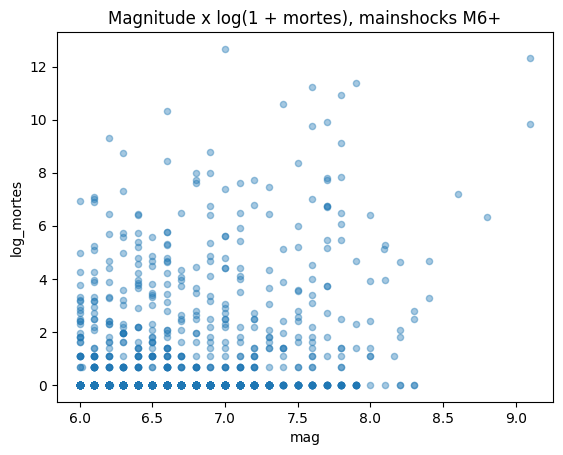

In [4]:
import matplotlib.pyplot as plt

ax = eventos.plot.scatter(x="mag", y="log_mortes", alpha=0.4)
ax.set_title("Magnitude x log(1 + mortes), mainshocks M6+")
plt.show()